# MIRA-CSI · saved-model quick start

**Abdessamad Bourkibate** · [Software and citation](https://github.com/ABDESSAMAD-BOURKIBATE/mira-csi)

This notebook downloads the verified public release, runs a saved model on a
recorded CSI example, and displays its actual probabilities. A CPU is sufficient.
It performs inference; it does not rerun or claim to reproduce all 60 training runs.
Full study settings and results are in the repository's evaluation directory.

The example is selected by manifest order and is misclassified. Its failure is
retained. Input is recorded CSI, not a live view of the notebook user.


## 1. Locate the source and check dependencies

In [1]:
from pathlib import Path
import sys, subprocess, json, hashlib, zipfile
import numpy as np
import torch
import matplotlib.pyplot as plt

root = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / "predict.py").exists()), None)
if root is None:
    root = Path.cwd() / "mira-csi"
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--branch", "v0.1.0",
                        "https://github.com/ABDESSAMAD-BOURKIBATE/mira-csi.git", str(root)], check=True)
assert (root / "predict.py").exists()
print("Python:", sys.version.split()[0], "PyTorch:", torch.__version__, "Inference device: CPU")


Python: 3.12.14 PyTorch: 2.11.0+cpu Inference device: CPU


## 2. Verify and load the public release

The SHA256 check precedes extraction. Only the named model and example files are extracted.

In [2]:
from urllib.request import urlretrieve
cache = root / ".cache"
cache.mkdir(exist_ok=True)
archive = cache / "mira-csi-verified-results.zip"
if not archive.exists():
    urlretrieve("https://github.com/ABDESSAMAD-BOURKIBATE/mira-csi/releases/download/v0.1.0/mira-csi-verified-results.zip", archive)
assert hashlib.sha256(archive.read_bytes()).hexdigest() == "2f50e1886a84837bf8e51fb80ec418fa06f8c46da9ba108e675f36f5bee1dfbd"
members = ["results/checkpoints/mira_csi_E3_s20261026.pt",
           "results/runs/mira_csi_E3_s20261026.json", "results/demo_input.npy",
           "results/demo_observed.npy", "results/demo_inference.json"]
with zipfile.ZipFile(archive) as bundle:
    for name in members:
        target = (root / name).resolve()
        assert target.is_relative_to(root.resolve())
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(bundle.read(name))
print("Release SHA256 verified; model and recorded example ready.")


Release SHA256 verified; model and recorded example ready.


## 3. Run the published predictor

In [3]:
base = [sys.executable, "predict.py", "--checkpoint", members[0], "--input", "results/demo_input.npy",
        "--calibration", members[1]]
reference = json.loads((root / "results/demo_inference.json").read_text())
predictions = []
for expected, extra in zip(reference, [[], ["--observed", "results/demo_observed.npy"]]):
    run = subprocess.run(base + extra, cwd=root, check=True, capture_output=True, text=True)
    actual = json.loads(run.stdout)
    assert actual["prediction"] == expected["prediction"]
    np.testing.assert_allclose(list(actual["probabilities"].values()), list(expected["probabilities"].values()), atol=1e-6, rtol=1e-6)
    predictions.append(actual)
    print(expected["condition"], "| true:", expected["truth"], "| predicted:", actual["prediction"],
          "| max probability:", round(max(actual["probabilities"].values()), 4))


Complete | true: sit | predicted: pick_up | max probability: 0.3259


Block 50% | true: sit | predicted: sit_down | max probability: 0.2543


## 4. Inspect the input and output

Colors in the left panel are scaled CSI amplitude, not temperature or a body image. The teal probability bar marks the true class.

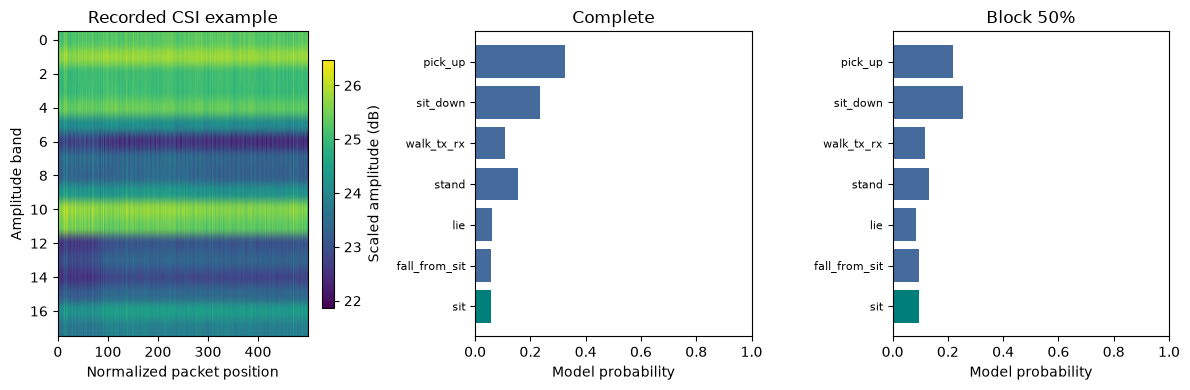

In [4]:
x = np.load(root / "results/demo_input.npy", allow_pickle=False)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
im = axes[0].imshow(x, aspect="auto", cmap="viridis")
axes[0].set(title="Recorded CSI example", xlabel="Normalized packet position", ylabel="Amplitude band")
fig.colorbar(im, ax=axes[0], label="Scaled amplitude (dB)", fraction=.045)
for ax, prediction, expected in zip(axes[1:], predictions, reference):
    names = list(prediction["probabilities"])
    ax.barh(names, list(prediction["probabilities"].values()),
            color=["#007e7b" if name == expected["truth"] else "#456a9c" for name in names])
    ax.set(xlim=(0, 1), xlabel="Model probability", title=expected["condition"])
    ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
plt.show()


## Interpretation

Both saved-model inference cases should match the released probabilities within
the specified floating-point tolerance. This checks execution and numerical
portability, not generalization accuracy. The first-file failure remains visible.
For the full five-seed evaluation, use `run_experiment.py` and the fixed manifest,
then independently verify saved probabilities with `verify_results.py`.
